# 01 — Dasar MQTT dengan Python (paho-mqtt)

Notebook ini menguji broker Mosquitto lokal dan memperlihatkan pola dasar **publish / subscribe**.

**Sebelum mulai:** jalankan `start_broker.bat` (atau `start_all.bat`) agar broker aktif di `localhost:1883`.

| Istilah | Arti |
|---|---|
| Broker | Server perantara pesan (Mosquitto) |
| Topic | Alamat pesan, mis. `kelas/iot/suhu` |
| Publish | Mengirim pesan ke sebuah topic |
| Subscribe | Berlangganan pesan dari topic (boleh wildcard `+` dan `#`) |

In [1]:
import json, random, time
from datetime import datetime

import paho.mqtt.client as mqtt
import pandas as pd

BROKER = "localhost"   # ganti dengan IP broker lain bila perlu
PORT = 1883
TOPIC_BASE = "kelas/iot"
print("paho-mqtt", mqtt.__version__ if hasattr(mqtt, "__version__") else "")

paho-mqtt 


## 1. Subscriber — menampung pesan yang masuk

In [6]:
pesan_masuk = []

def on_connect(client, userdata, flags, reason_code, properties):
    print("Subscriber terhubung:", reason_code)
    client.subscribe(f"{TOPIC_BASE}/#")   # semua sub-topic

def on_message(client, userdata, msg):
    data = json.loads(msg.payload.decode())
    data["topic"] = msg.topic
    pesan_masuk.append(data)

sub = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2, client_id="nb-subscriber")
sub.on_connect = on_connect
sub.on_message = on_message
sub.connect(BROKER, PORT)
sub.loop_start()          # jalan di background thread

Subscriber terhubung: Success


<MQTTErrorCode.MQTT_ERR_SUCCESS: 0>

## 2. Publisher — simulasi sensor suhu & kelembapan

In [3]:
pub = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2, client_id="nb-publisher")
pub.connect(BROKER, PORT)
pub.loop_start()

for i in range(20):
    payload = {
        "waktu": datetime.now().isoformat(timespec="seconds"),
        "suhu": round(27 + random.uniform(-1.5, 1.5), 2),
        "kelembapan": round(70 + random.uniform(-5, 5), 2),
    }
    pub.publish(f"{TOPIC_BASE}/node1", json.dumps(payload), qos=1)
    time.sleep(0.25)

time.sleep(1)
print(f"Pesan diterima subscriber: {len(pesan_masuk)}")

Pesan diterima subscriber: 20


## 3. Olah data dengan pandas & matplotlib

,waktu,suhu,kelembapan,topic
15,2026-10-23 11:13:32,26.33,65.49,kelas/iot/node1
16,2026-10-23 11:13:32,26.04,65.86,kelas/iot/node1
17,2026-10-23 11:13:33,27.54,67.12,kelas/iot/node1
18,2026-10-23 11:13:33,28.08,69.32,kelas/iot/node1
19,2026-10-23 11:13:33,27.89,67.63,kelas/iot/node1


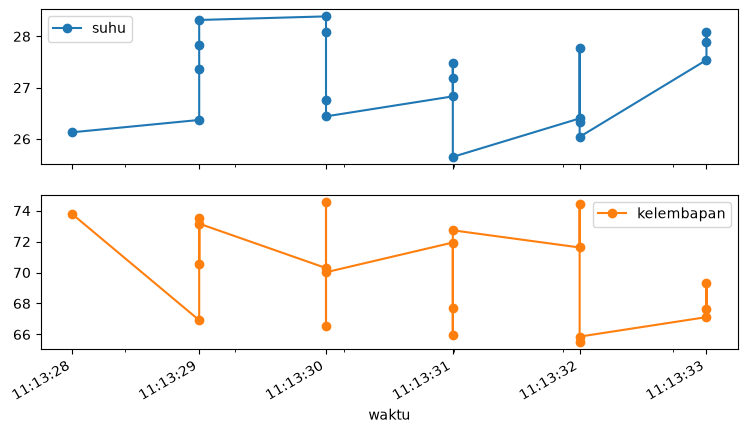

In [4]:
df = pd.DataFrame(pesan_masuk)
df["waktu"] = pd.to_datetime(df["waktu"])
display(df.tail())

ax = df.plot(x="waktu", y=["suhu", "kelembapan"], subplots=True, figsize=(9, 5), marker="o")

## 4. Tutup koneksi

In [7]:
for c in (pub, sub):
    c.loop_stop()
    c.disconnect()
print("Koneksi ditutup.")

Koneksi ditutup.
